In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
from matplotlib.patches import Polygon
import sunpy
import sunpy.map
from sunpy.coordinates import get_earth, propagate_with_solar_surface
import dkist 
import dask.array as da
import h5py
from astropy.time import Time
from astropy.io import ascii, fits
from astropy.wcs import WCS
from astropy.visualization import (ImageNormalize, 
                    SqrtStretch, AsinhStretch,
                    ZScaleInterval, SinhStretch)
import astropy.units as u
from ndcube import NDCube
from ndcube.wcs.tools import unwrap_wcs_to_fitswcs
from fancy_colorbar import wcs_scalebar, plot_colorbar
from sun_blinker import ImageBlinker

        Use pytest instead. [astropy.tests.runner]
        Use pytest instead. [astropy.utils.decorators]
        Use pytest instead. [astropy.tests.runner]
        Use pytest instead. [astropy.utils.decorators]


In [2]:
import importlib
import sun_blinker
importlib.reload(sun_blinker)
from sun_blinker import ImageBlinker

In [3]:
file_Gband_pr = h5py.File("../../data/pid_1_123_aux/plot_ready/Gband_AEZDV_pr.hdf5")
Gband_pr_set = file_Gband_pr["vbi_img"]
Gband_pr_da = da.from_array(Gband_pr_set, chunks=(1, 4096 - 128*2, 4096 - 128*2))
Gband_date_obs = Time(ascii.read("../../data/pid_1_123_aux/plot_ready/Gband_AEZDV_date_avg.txt")["DATE-AVG"])

file_Hbeta_pr = h5py.File("../../data/pid_1_123_aux/plot_ready/Hbeta_BJOLO_pr.hdf5")
Hbeta_pr_set = file_Hbeta_pr["vbi_img"]
Hbeta_pr_da = da.from_array(Hbeta_pr_set, chunks=(1, 4096 - 128*2, 4096 - 128*2))
Hbeta_date_obs = Time(ascii.read("../../data/pid_1_123_aux/plot_ready/Hbeta_BJOLO_date_avg.txt")["DATE-AVG"])

file_CaIIK_pr = h5py.File("../../data/pid_1_123_aux/plot_ready/CaIIK_BZPOW_pr.hdf5")
CaIIK_pr_set = file_CaIIK_pr["vbi_img"]
CaIIK_pr_da = da.from_array(CaIIK_pr_set, chunks=(1, 4096 - 128*2, 4096 - 128*2))
CaIIK_date_obs = Time(ascii.read("../../data/pid_1_123_aux/plot_ready/CaIIK_BZPOW_date_avg.txt")["DATE-AVG"])

file_TiO_pr = h5py.File("../../data/pid_1_123_aux/plot_ready/TiO_BNRPZ_pr.hdf5")
TiO_pr_set = file_TiO_pr["vbi_img"]
TiO_pr_da = da.from_array(TiO_pr_set, chunks=(1, 4096 - 128*2, 4096 - 128*2))
TiO_date_obs = Time(ascii.read("../../data/pid_1_123_aux/plot_ready/TiO_BNRPZ_date_avg.txt")["DATE-AVG"])

file_Halpha_pr = h5py.File("../../data/pid_1_123_aux/plot_ready/Halpha_BLZNL_pr.hdf5")
Halpha_pr_set = file_Halpha_pr["vbi_img"]
Halpha_pr_da = da.from_array(Halpha_pr_set, chunks=(1, 4096 - 128*2, 4096 - 128*2))
Halpha_date_obs = Time(ascii.read("../../data/pid_1_123_aux/plot_ready/Halpha_BLZNL_date_avg.txt")["DATE-AVG"])

In [4]:
dkist_vbi_target_header = fits.getheader("../../data/pid_1_123_aux/plot_ready/dkist_target_wcs_header_before_crop.fits",
                                        ignore_missing_simple=True)

dkist_vbi_target_data = np.zeros((4096,4096))

dkist_vbi_target_cube = NDCube(dkist_vbi_target_data,WCS(dkist_vbi_target_header, naxis=2))
dkist_vbi_target_cube_crop = dkist_vbi_target_cube[128:-128,128:-128]
dkist_vbi_target_cube_crop_rebin = dkist_vbi_target_cube_crop.rebin((8,8))

target_wcs = unwrap_wcs_to_fitswcs(dkist_vbi_target_cube_crop.wcs)[0]
target_wcs_rebin = dkist_vbi_target_cube_crop_rebin.wcs

Set MJD-BEG to 59876.791095 from DATE-BEG.
Set MJD-AVG to 59876.791095 from DATE-AVG.
Set MJD-END to 59876.791095 from DATE-END'. [astropy.wcs.wcs]
Set OBSGEO-B to    20.706700 from OBSGEO-[XYZ].
Set OBSGEO-H to     3063.997 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


In [5]:
sotsp_dateobs_map = sunpy.map.Map("../../data/pid_1_123_aux/SOTSP/sotsp_dateobs_warp_to_hmi.fits")
sotsp_dateobs_map.meta["rsun_ref"] = 695700000.

In [6]:
with propagate_with_solar_surface():
    sotsp_dateobs_map_repro = sotsp_dateobs_map.reproject_to(target_wcs)

INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]


In [7]:
sotsp_dateobs_repro_tstart = np.nanmin(sotsp_dateobs_map_repro.data)
sotsp_dateobs_repro_tend = np.nanmax(sotsp_dateobs_map_repro.data)
sotsp_dateobs_diff_map = sunpy.map.Map(
    (sotsp_dateobs_map_repro.data - sotsp_dateobs_repro_tstart)*86400,
    sotsp_dateobs_map_repro.meta
)

In [8]:
sotsp_dateobs_repro_tstart_time = Time(sotsp_dateobs_repro_tstart, format="mjd")
sotsp_dateobs_repro_tend_time = Time(sotsp_dateobs_repro_tend, format="mjd")

In [9]:
sotsp_dateobs_repro_tstart_time.isot, sotsp_dateobs_repro_tend_time.isot

('2022-10-24T19:10:04.393', '2022-10-24T19:18:40.215')

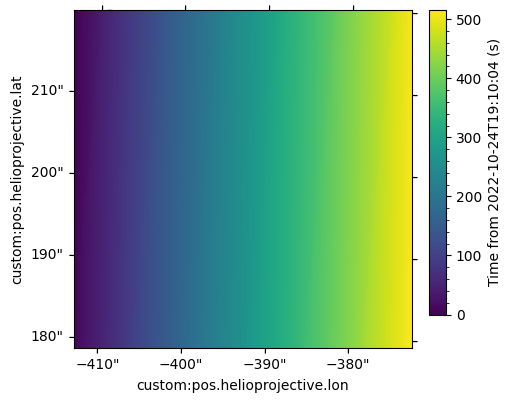

In [10]:
fig = plt.figure(figsize=(5,5), layout="constrained")
ax = fig.add_subplot(111, projection=target_wcs)
im = ax.imshow(
    sotsp_dateobs_diff_map.data, 
    origin="lower" 
)

clb, clb_ax = plot_colorbar(im, ax, bbox_to_anchor=[1.05, 0.1, 0.05, 0.9])
clb.set_label(f"Time from {sotsp_dateobs_repro_tstart_time.strftime('%Y-%m-%dT%H:%M:%S')} (s)")

In [33]:
def get_idx_nearest(dateobs_img, dateobs_list):

    idx = np.searchsorted(dateobs_list, dateobs_img)
    idx = np.clip(idx, 1, len(dateobs_list) - 1)

    left = dateobs_list[idx - 1]
    right = dateobs_list[idx]

    idx_nearest = np.where(
        np.abs(dateobs_img - left) <= np.abs(dateobs_img - right),
        idx - 1,
        idx
    )

    return idx_nearest

In [42]:
def get_syn_map(pr_data, dateobs_img, dateobs_list):
    idx_nearest = get_idx_nearest(dateobs_img, dateobs_list)

    out = np.full(idx_nearest.shape, np.nan, dtype=pr_data.dtype)

    for ii in range(pr_data.shape[0]):
        mask = idx_nearest == ii
        if not mask.any():
            continue

        frame = pr_data[ii]
        out[mask] = frame[mask]

    return out

In [35]:
idx_nearest_Gband = idx_nearest(sotsp_dateobs_map_repro.data, Gband_date_obs.mjd)

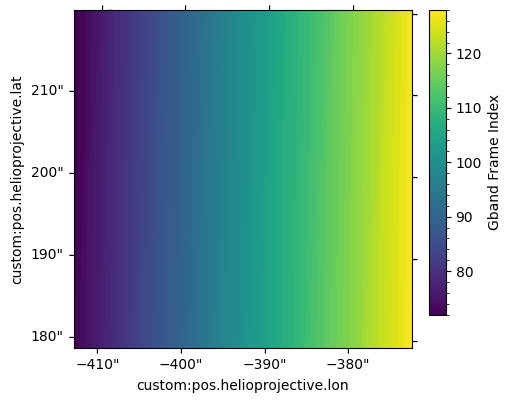

In [60]:
fig = plt.figure(figsize=(5,5), layout="constrained")
ax = fig.add_subplot(111, projection=target_wcs)
im = ax.imshow(
    idx_nearest_Gband, 
    origin="lower",
    interpolation="nearest" 
)

clb, clb_ax = plot_colorbar(im, ax, bbox_to_anchor=[1.05, 0.1, 0.05, 0.9])
clb.set_label(f"Gband Frame Index")

In [43]:
Gband_syn_raster = get_syn_map(Gband_pr_da, sotsp_dateobs_map_repro.data, Gband_date_obs.mjd)

In [67]:
np.save("../../data/pid_1_123_aux/VBI_syn_raster/Gband_syn_raster.npy", Gband_syn_raster)

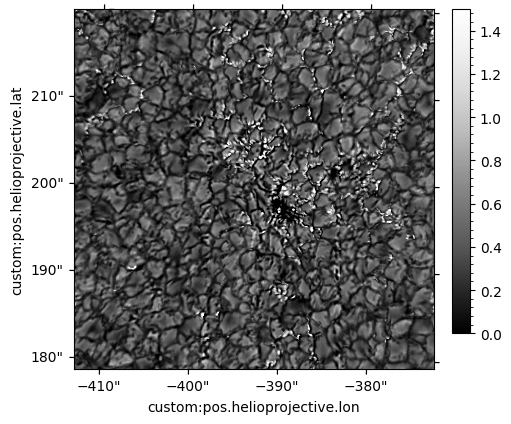

In [46]:
fig = plt.figure(figsize=(5,5), layout="constrained")
ax = fig.add_subplot(111, projection=target_wcs)

im = ax.imshow(Gband_syn_raster,
    origin="lower",
    cmap="Greys_r",
    interpolation="nearest",
    vmin=0,
    vmax=1.5
    )

clb, clb_ax = plot_colorbar(im, ax, bbox_to_anchor=[1.05, 0.1, 0.05, 0.9])

In [48]:
sotsp_dateobs_repro_mid_time = sotsp_dateobs_repro_tstart_time + (sotsp_dateobs_repro_tend_time - sotsp_dateobs_repro_tstart_time)/2

In [53]:
Gband_mid_point_index = np.argmin(np.abs(Gband_date_obs.mjd - sotsp_dateobs_repro_mid_time.mjd))
Gband_mid_point_index

np.int64(100)

In [69]:
ImageBlinker(
    Gband_syn_raster,
    Gband_pr_da[Gband_mid_point_index,:,:].compute(),
    cmap1="Greys_r",
    cmap2="Greys_r",
    norm1=ImageNormalize(vmin=0, vmax=1.5),
    norm2=ImageNormalize(vmin=0, vmax=1.5),
    title1="Gband Synthetic Raster",
    title2="Gband SOT/SP DATE-AVG",
    save_fname="../../figs/test_figs/Gband_syn_raster.gif",
    fps=1
)

In [70]:
TiO_syn_raster = get_syn_map(TiO_pr_da, sotsp_dateobs_map_repro.data, TiO_date_obs.mjd)
np.save("../../data/pid_1_123_aux/VBI_syn_raster/TiO_syn_raster.npy", TiO_syn_raster)

In [71]:
TiO_mid_point_index = np.argmin(np.abs(TiO_date_obs.mjd - sotsp_dateobs_repro_mid_time.mjd))
TiO_mid_point_index

np.int64(159)

In [73]:
ImageBlinker(
    TiO_syn_raster,
    TiO_pr_da[TiO_mid_point_index,:,:].compute(),
    cmap1="Greys_r",
    cmap2="Greys_r",
    norm1=ImageNormalize(vmin=0, vmax=1.5),
    norm2=ImageNormalize(vmin=0, vmax=1.5),
    title1="TiO Synthetic Raster",
    title2="TiO SOT/SP DATE-AVG",
    save_fname="../../figs/test_figs/TiO_syn_raster.gif",
    fps=1
)

In [74]:
Hbeta_syn_raster = get_syn_map(Hbeta_pr_da, sotsp_dateobs_map_repro.data, Hbeta_date_obs.mjd)
np.save("../../data/pid_1_123_aux/VBI_syn_raster/Hbeta_syn_raster.npy", Hbeta_syn_raster)

In [75]:
Hbeta_mid_point_index = np.argmin(np.abs(Hbeta_date_obs.mjd - sotsp_dateobs_repro_mid_time.mjd))
Hbeta_mid_point_index

np.int64(99)

In [79]:
ImageBlinker(
    Hbeta_syn_raster,
    Hbeta_pr_da[Hbeta_mid_point_index,:,:].compute(),
    cmap1="Greys_r",
    cmap2="Greys_r",
    norm1=ImageNormalize(vmin=0, vmax=1.2),
    norm2=ImageNormalize(vmin=0, vmax=1.2),
    title1="Hbeta Synthetic Raster",
    title2="Hbeta SOT/SP DATE-AVG",
    save_fname="../../figs/test_figs/Hbeta_syn_raster.gif",
    fps=1
)

In [77]:
Halpha_syn_raster = get_syn_map(Halpha_pr_da, sotsp_dateobs_map_repro.data, Halpha_date_obs.mjd)
np.save("../../data/pid_1_123_aux/VBI_syn_raster/Halpha_syn_raster.npy", Halpha_syn_raster)

In [78]:
Halpha_mid_point_index = np.argmin(np.abs(Halpha_date_obs.mjd - sotsp_dateobs_repro_mid_time.mjd))
Halpha_mid_point_index

np.int64(160)

In [81]:
ImageBlinker(
    Halpha_syn_raster,
    Halpha_pr_da[Halpha_mid_point_index,:,:].compute(),
    cmap1="Greys_r",
    cmap2="Greys_r",
    norm1=ImageNormalize(vmin=0.1, vmax=0.8),
    norm2=ImageNormalize(vmin=0.1, vmax=0.8),
    title1="Halpha Synthetic Raster",
    title2="Halpha SOT/SP DATE-AVG",
    save_fname="../../figs/test_figs/Halpha_syn_raster.gif",
    fps=1
)

In [82]:
CaIIK_syn_raster = get_syn_map(CaIIK_pr_da, sotsp_dateobs_map_repro.data, CaIIK_date_obs.mjd)
np.save("../../data/pid_1_123_aux/VBI_syn_raster/CaIIK_syn_raster.npy", CaIIK_syn_raster)

In [83]:
CaIIK_mid_point_index = np.argmin(np.abs(CaIIK_date_obs.mjd - sotsp_dateobs_repro_mid_time.mjd))
CaIIK_mid_point_index

np.int64(100)

In [87]:
ImageBlinker(
    CaIIK_syn_raster,
    CaIIK_pr_da[CaIIK_mid_point_index,:,:].compute(),
    cmap1="Greys_r",
    cmap2="Greys_r",
    norm1=ImageNormalize(vmin=0, vmax=1.5),
    norm2=ImageNormalize(vmin=0, vmax=1.5),
    title1="Ca II K Synthetic Raster",
    title2="Ca II K SOT/SP DATE-AVG",
    save_fname="../../figs/test_figs/CaIIK_syn_raster.gif",
    fps=1
)